# Phase 1 — Reproducibility Verification
## Road Surface Damage Classification

### Objective
Independently verify the team's prepared classification data and
reproduce evaluation of the saved fine-tuned ResNet18 checkpoint.

### Scope
- Check class labels and parent-image split consistency.
- Verify that Norway is reserved for testing.
- Check the presence and readability of all referenced crops.
- Evaluate the saved checkpoint on 11,229 test crops.
- Compare accuracy, macro-F1, top-2 accuracy, and ECE with the
  original results using an absolute tolerance of 1e-6.
- Save predictions, metrics, environment details, and input fingerprints.

This notebook evaluates an existing checkpoint. It does not retrain
the models or independently evaluate the scratch and frozen checkpoints.

### How to Run
1. Keep this notebook inside the project's Phase1_Reproducibility folder.
2. Select the Python environment containing the required packages.
3. Update DATA_SEARCH_ROOT to the folder containing the data and
   original results on your computer.
4. Ensure that the search folder contains exactly one copy of each
   required input file and one original test_comparison.csv.
5. Restart the kernel, then run all cells from top to bottom.

Each complete run saves its outputs in a new timestamped folder
under Phase1_Reproducibility/results.

------------------------------
## 1. Environment and Package Versions

This cell records the Python version, interpreter location, working
directory, and installed versions of the main project packages.

These details document the environment used for local verification
and help investigate differences when running on another computer.

Finding a package version confirms that it is installed. The next
cell checks whether the packages can actually be imported.

In [1]:
#1
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Working folder:", Path.cwd())

for package in ["ipykernel", "numpy", "pandas", "matplotlib",
                "Pillow", "scikit-learn", "torch", "torchvision", "wandb"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

Python: 3.14.6
Executable: c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\python.exe
Working folder: c:\Users\PC\Downloads\project\project\road-damage-detection-feature-m2-m3-classification\road-damage-detection-feature-m2-m3-classification\Phase1_Reproducibility
ipykernel: 7.3.0
numpy: 2.5.2
pandas: 3.0.6
matplotlib: 3.11.2
Pillow: 12.3.0
scikit-learn: 1.9.1
torch: 2.14.1
torchvision: 0.29.1
wandb: 0.22.3


--------------------------------
## 2. Import Libraries and Check PyTorch

This cell imports the libraries needed for data handling, image
processing, visualization, and model evaluation.

Successful imports confirm that the libraries can load in the
selected Python environment. The cell also displays the PyTorch
and Torchvision versions and checks whether CUDA is available.

This verification uses the CPU. CUDA availability is not required.

In [2]:
#2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
import sklearn
import torch
import torchvision
import wandb

print("All imports passed.")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")

All imports passed.
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CUDA available: False
Device: CPU


--------------------------------
## 3. Locate the Project Root

This cell searches the current working directory and its parent
folders for the project root, identified by the scripts and
road_damage_m2_m3_colab folders.

Locating the root automatically avoids hard-coding the full project
path. Execution stops if the project root cannot be found.

The output also checks whether the data and reports folders exist.
Their presence does not confirm that the required input files are
inside them; those files are located in the following steps.

In [3]:
#3
from pathlib import Path

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "scripts").is_dir()
     and (p / "road_damage_m2_m3_colab").is_dir()),
    None
)

assert PROJECT_ROOT is not None, "Project folder not found."

print("Project root:", PROJECT_ROOT)
print("Data folder exists:", (PROJECT_ROOT / "data").is_dir())
print("Reports folder exists:", (PROJECT_ROOT / "reports").is_dir())

Project root: C:\Users\PC\Downloads\project\project\road-damage-detection-feature-m2-m3-classification\road-damage-detection-feature-m2-m3-classification
Data folder exists: True
Reports folder exists: True


-----------------------
## 4. Define the Required Input Files

This cell lists the four input files needed for verification:

- split_manifest.csv: assigns original images to dataset splits.
- annotations.csv: contains the original damage annotations.
- classification_manifest.csv: links classification crops to their
  labels, parent images, and splits.
- classification_crops.zip: contains the cropped damage images.

This cell defines the filenames only. The next step searches for
their actual locations.

In [4]:
#4
required_files = [
    "split_manifest.csv",
    "annotations.csv",
    "classification_manifest.csv",
    "classification_crops.zip",
]

print("Required input filenames configured.")

Required input filenames configured.


-------------------------------
## 5. Configure the Input Folder and Locate Files

Set DATA_SEARCH_ROOT to the local folder containing the project
data and original results. Update this path on another computer.

This cell searches the folder and its subfolders for each required
input file. It stops with a descriptive error if the search folder
does not exist, an input is missing, or multiple copies are found.

Execution continues only when exactly one copy of each required
input has been located.

In [5]:
# 5 — Local input configuration
# Change this folder when running on another computer.
DATA_SEARCH_ROOT = Path(r"C:\Users\PC\Downloads\project")

assert DATA_SEARCH_ROOT.is_dir(), (
    f"Input folder does not exist: {DATA_SEARCH_ROOT}\n"
    "Update DATA_SEARCH_ROOT to your local data and results folder."
)

matches = {}

for name in required_files:
    found = sorted(DATA_SEARCH_ROOT.rglob(name))

    if not found:
        raise FileNotFoundError(
            f"Missing input: {name}\n"
            f"Search folder: {DATA_SEARCH_ROOT}"
        )

    if len(found) > 1:
        paths = "\n".join(str(path) for path in found)
        raise ValueError(
            f"Multiple copies found for {name}:\n{paths}\n"
            "Choose a narrower DATA_SEARCH_ROOT containing one copy."
        )

    matches[name] = found
    print(f"{name}: FOUND")

print("PASS: All required inputs located uniquely.")

split_manifest.csv: FOUND
annotations.csv: FOUND
classification_manifest.csv: FOUND
classification_crops.zip: FOUND
PASS: All required inputs located uniquely.


--------------------------------
## 6. Load the Manifests and Summarize the Dataset

This cell requires exactly one match for each input filename,
then loads the three CSV files and records the crop ZIP path.

It reports the number of original image records, annotations,
and classification crops. A summary table shows the crop counts
for each class in the training, validation, and test splits.

These counts describe the prepared dataset. Split consistency
and crop file integrity are checked in the following cells.

In [6]:
#6
import pandas as pd

assert all(len(matches[name]) == 1 for name in required_files), \
    "Expected exactly one copy of each required file."

DATA_FILES = {
    name: matches[name][0]
    for name in required_files
}

split_df = pd.read_csv(DATA_FILES["split_manifest.csv"])
annotations_df = pd.read_csv(DATA_FILES["annotations.csv"])
classification_df = pd.read_csv(DATA_FILES["classification_manifest.csv"])
CROPS_ZIP = DATA_FILES["classification_crops.zip"]

print("Original images:", len(split_df))
print("Annotations:", len(annotations_df))
print("Classification crops:", len(classification_df))

display(
    pd.crosstab(
        classification_df["split"],
        classification_df["class"]
    ).reindex(["train", "val", "test"])
)

Original images: 38384
Annotations: 55002
Classification crops: 32692


class,D00,D10,D20,D40
split,,,,
train,3000,3000,3000,3000
val,5092,2758,1095,518
test,8570,1730,468,461


-------------------------------
## 7. Validate Labels and Split Consistency

This cell checks that required crop fields are populated, class
codes are valid, and the expected dataset splits are present.

It also checks for duplicate crop paths and duplicate parent-image
IDs in the split manifest. Each crop must belong to a known parent
image and use the same split as that parent.

Keeping all crops from one parent image in the same split helps
prevent data leakage. Norway images must appear only in the test split.

These checks validate metadata consistency; they do not verify
the visual correctness of every label or detect duplicate image content.

In [7]:
#7
required_columns = ["crop_path", "image_id", "split", "class"]

assert classification_df[required_columns].notna().all().all(), \
    "Missing values found."

assert classification_df["class"].isin(
    ["D00", "D10", "D20", "D40"]
).all(), "Unknown class."

assert set(classification_df["split"]) == {"train", "val", "test"}, \
    "Unexpected splits."

assert not classification_df["crop_path"].duplicated().any(), \
    "Duplicate crop paths."

assert not split_df["image_id"].duplicated().any(), \
    "Duplicate parent image IDs."

assert classification_df.groupby("image_id")["split"].nunique().max() == 1, \
    "Parent image appears across splits."

parent_splits = split_df.set_index("image_id")["split"]
expected_split = classification_df["image_id"].map(parent_splits)

assert expected_split.notna().all(), "Parent image missing."
assert expected_split.eq(classification_df["split"]).all(), \
    "Crop split does not match its parent."

norway = split_df[
    split_df["country"].astype(str).str.contains("Norway", case=False)
]
assert len(norway) > 0 and norway["split"].eq("test").all(), \
    "Norway holdout check failed."

print("PASS: Labels and crop paths are valid.")
print("PASS: Parent-image split assignments are consistent.")
print("PASS: Norway is reserved for testing.")

PASS: Labels and crop paths are valid.
PASS: Parent-image split assignments are consistent.
PASS: Norway is reserved for testing.


-----------------------------
## 8. Verify Crop Availability in the ZIP

This cell standardizes crop paths from the classification manifest
and ZIP archive so they can be compared across different path formats.

It checks that every crop referenced in the manifest exists inside
the ZIP, without extracting the archive. Execution stops if any
referenced crop is missing.

This confirms file availability. The next cell checks whether
the images can actually be opened and decoded.

In [8]:
#8
import zipfile

def relative_crop_path(path):
    return str(path).replace("\\", "/").split("classification_crops/")[-1]

expected_paths = set(
    classification_df["crop_path"].map(relative_crop_path)
)

with zipfile.ZipFile(CROPS_ZIP) as archive:
    archived_paths = {
        relative_crop_path(item.filename)
        for item in archive.infolist()
        if not item.is_dir()
    }

missing = expected_paths - archived_paths

print("Expected crops:", len(expected_paths))
print("Missing crops:", len(missing))

assert not missing, f"Missing examples: {sorted(missing)[:5]}"
print("PASS: All referenced crops exist in the ZIP.")

Expected crops: 32692
Missing crops: 0
PASS: All referenced crops exist in the ZIP.


-----------------------
## 9. Check Crop Image Readability

This cell opens and fully decodes every referenced crop directly
from the ZIP archive and checks that its dimensions are positive.

Progress is displayed every 5,000 crops. Any image that cannot
be read is recorded with its path and error message.

Zero unreadable crops confirms that all referenced images decoded
successfully. This does not assess visual quality or label correctness.

In [9]:
#9
from PIL import Image

bad_images = []

with zipfile.ZipFile(CROPS_ZIP) as archive:
    members = {
        relative_crop_path(item.filename): item
        for item in archive.infolist()
        if not item.is_dir()
    }

    for index, path in enumerate(sorted(expected_paths), start=1):
        try:
            with archive.open(members[path]) as file:
                with Image.open(file) as image:
                    image.load()
                    if min(image.size) <= 0:
                        raise ValueError("Invalid image dimensions")
        except Exception as error:
            bad_images.append((path, str(error)))

        if index % 5000 == 0:
            print(f"Checked: {index}/{len(expected_paths)}")

print("Checked crops:", len(expected_paths))
print("Unreadable crops:", len(bad_images))

if bad_images:
    display(pd.DataFrame(bad_images, columns=["crop_path", "error"]))
else:
    print("PASS: All referenced crops decoded successfully.")

Checked: 5000/32692
Checked: 10000/32692
Checked: 15000/32692
Checked: 20000/32692
Checked: 25000/32692
Checked: 30000/32692
Checked crops: 32692
Unreadable crops: 0
PASS: All referenced crops decoded successfully.


---------------------
## 10. Locate the Original Model Results

This cell searches DATA_SEARCH_ROOT for test_comparison.csv,
which identifies candidate folders containing the team's saved results.

For each candidate folder, it checks whether best.pt exists for
the scratch, frozen, and fine-tuned models.

These checks confirm checkpoint file availability only.
The next cell requires exactly one results folder before proceeding.

In [10]:
#10
result_candidates = sorted(
    DATA_SEARCH_ROOT.rglob("test_comparison.csv")
)

for path in result_candidates:
    print("Results folder:", path.parent)

    for model_name in ["scratch", "frozen", "finetune"]:
        checkpoint = path.parent / model_name / "best.pt"
        status = "FOUND" if checkpoint.is_file() else "NOT FOUND"
        print(f"  {model_name}: {status}")

if not result_candidates:
    print("No saved test comparison found.")

Results folder: C:\Users\PC\Downloads\project\Results-20261024T145747Z-1-001\Results\m2_m3\alharby6626\simple_v1
  scratch: FOUND
  frozen: FOUND
  finetune: FOUND


----------------------
## 11. Load the Saved Experiment Configuration

This cell identifies the original results folder and checks that
the fine-tuned model configuration and checkpoint exist.

The seed, image size, batch size, and class order are read from
config.json. Preserving class order is essential for interpreting
the model's outputs correctly.

The metric comparison tolerance and ECE bin count are also defined
here. The original test results are displayed as the reference
for local verification.

In [11]:
# 11 — Load the saved experiment configuration
import json

if len(result_candidates) != 1:
    raise ValueError(
        "Expected one original results folder, "
        f"but found {len(result_candidates)}. "
        "Check DATA_SEARCH_ROOT."
    )

ORIGINAL_RESULTS = result_candidates[0].parent
MODEL_NAME = "finetune"
METRIC_TOLERANCE = 1e-6
ECE_BINS = 10

config_path = ORIGINAL_RESULTS / MODEL_NAME / "config.json"
checkpoint = ORIGINAL_RESULTS / MODEL_NAME / "best.pt"

for path in [config_path, checkpoint]:
    if not path.is_file():
        raise FileNotFoundError(f"Required model file is missing: {path}")

with config_path.open(encoding="utf-8") as file:
    MODEL_CONFIG = json.load(file)

required_settings = ["seed", "image_size", "batch_size", "classes"]
missing_settings = [
    key for key in required_settings if key not in MODEL_CONFIG
]
if missing_settings:
    raise ValueError(f"Missing model settings: {missing_settings}")

SEED = int(MODEL_CONFIG["seed"])
IMAGE_SIZE = int(MODEL_CONFIG["image_size"])
BATCH_SIZE = int(MODEL_CONFIG["batch_size"])
CLASSES = list(MODEL_CONFIG["classes"])

assert IMAGE_SIZE > 0 and BATCH_SIZE > 0
assert len(CLASSES) == 4 and set(CLASSES) == {
    "D00", "D10", "D20", "D40"
}, "Unexpected class configuration."

print("Selected model:", MODEL_NAME)
print("Seed:", SEED)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Class order:", CLASSES)

print("\nOriginal test results:")
display(pd.read_csv(ORIGINAL_RESULTS / "test_comparison.csv"))

Selected model: finetune
Seed: 42
Image size: 224
Batch size: 32
Class order: ['D00', 'D10', 'D20', 'D40']

Original test results:


,model,selected_by_validation,accuracy,top2_accuracy,macro_f1,ece,loss,accuracy_ci95_low,accuracy_ci95_high
0,scratch,False,0.545463,0.868911,0.426692,0.083344,0.967799,0.532819,0.558487
1,frozen,False,0.573159,0.902841,0.485077,0.151021,1.021361,0.561010,0.586286
2,finetune,True,0.784487,0.948793,0.619348,0.065339,0.610277,0.774557,0.794425


----------------------
## 12. Prepare the Test Data Loader

This cell selects the test crops and maps class codes to numeric
labels using the class order loaded from the saved configuration.

Images are read directly from the ZIP, converted to RGB, and resized
using IMAGE_SIZE. ImageNet normalization matches the original
evaluation pipeline. No random augmentation is applied.

The loader uses BATCH_SIZE without shuffling.
num_workers=0 keeps data loading in the notebook process.

The first batch is inspected to confirm the image and label shapes.

In [12]:
#12
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import io

CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

test_rows = classification_df[
    classification_df["split"] == "test"
].reset_index(drop=True)

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    ),
])

class TestCropsDataset(Dataset):
    def __init__(self, rows, zip_path):
        self.rows = rows
        self.archive = zipfile.ZipFile(zip_path)
        self.members = {
            relative_crop_path(item.filename): item
            for item in self.archive.infolist()
            if not item.is_dir()
        }

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        path = relative_crop_path(row["crop_path"])
        content = self.archive.read(self.members[path])

        with Image.open(io.BytesIO(content)) as image:
            tensor = eval_transform(image.convert("RGB"))

        return tensor, CLASS_TO_ID[row["class"]]

test_dataset = TestCropsDataset(test_rows, CROPS_ZIP)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(test_loader))
print("Test crops:", len(test_dataset))
print("Batch shape:", tuple(images.shape))
print("Labels shape:", tuple(labels.shape))

Test crops: 11229
Batch shape: (32, 3, 224, 224)
Labels shape: (32,)


-------------------
## 13. Load the Checkpoint and Test Inference

This cell sets the Python, NumPy, and PyTorch random seeds using
the saved experiment seed.

It creates the original ResNet18 architecture with the configured
number of classes and loads the checkpoint selected in Step 11.
All learned parameters are restored from the checkpoint.

Strict loading checks parameter compatibility. Evaluation mode
and inference mode prepare the model for CPU evaluation.

A forward pass on the first test batch checks the output shape
and confirms that all predicted probabilities are finite.

Setting seeds does not guarantee identical results across all
hardware and software environments.

In [13]:
# 13 — Load the configured checkpoint and test inference
import random
from torch import nn
from torchvision import models

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))

state = torch.load(
    checkpoint,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state, strict=True)
model = model.to(device)
model.eval()

with torch.inference_mode():
    logits = model(images.to(device))
    probabilities = logits.softmax(dim=1)

assert probabilities.shape == (len(images), len(CLASSES))
assert torch.isfinite(probabilities).all()

print("Model:", MODEL_NAME)
print("Device:", device)
print("Seed:", SEED)
print("PASS: Saved model loaded successfully.")
print("PASS: Predictions generated for", len(images), "images.")
print("Output shape:", tuple(probabilities.shape))

Model: finetune
Device: cpu
Seed: 42
PASS: Saved model loaded successfully.
PASS: Predictions generated for 32 images.
Output shape: (32, 4)


----------------------------
## 14. Evaluate the Full Test Set

This cell runs the loaded model on every test batch and collects
the true labels and predicted class probabilities.

The class with the highest probability becomes the predicted label.
Checks confirm that the output count matches the test set size
and that all probabilities are finite.

Accuracy and macro-F1 are calculated and compared with the original
fine-tuned model results. Absolute differences and evaluation time
are displayed.

This reproduces evaluation of the saved checkpoint without retraining.

In [14]:
#14
import time
from sklearn.metrics import accuracy_score, f1_score

all_labels = []
all_probabilities = []
start = time.perf_counter()

model.eval()

with torch.inference_mode():
    for batch_index, (images, labels) in enumerate(test_loader, start=1):
        probabilities = model(images.to(device)).softmax(dim=1)

        all_labels.append(labels.numpy())
        all_probabilities.append(probabilities.cpu().numpy())

        if batch_index % 50 == 0:
            print(f"Processed batches: {batch_index}/{len(test_loader)}")

y_true = np.concatenate(all_labels)
y_prob = np.concatenate(all_probabilities)
y_pred = y_prob.argmax(axis=1)

assert len(y_true) == len(test_rows)
assert np.isfinite(y_prob).all()

local_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_f1": f1_score(
        y_true, y_pred,
        labels=range(len(CLASSES)),
        average="macro",
        zero_division=0
    ),
}

original = pd.read_csv(
    ORIGINAL_RESULTS / "test_comparison.csv"
).set_index("model").loc[MODEL_NAME]

comparison = pd.DataFrame({
    "Original": {key: original[key] for key in local_metrics},
    "Local": local_metrics,
})
comparison["Absolute difference"] = (
    comparison["Local"] - comparison["Original"]
).abs()

display(comparison)
print(f"Evaluation time: {time.perf_counter() - start:.1f} seconds")

Processed batches: 50/351
Processed batches: 100/351
Processed batches: 150/351
Processed batches: 200/351
Processed batches: 250/351
Processed batches: 300/351
Processed batches: 350/351


,Original,Local,Absolute difference
accuracy,0.784487,0.784487,0.0
macro_f1,0.619348,0.619348,0.0


Evaluation time: 220.2 seconds


---------------------
## 15. Save Local Evaluation Outputs

This cell creates a new timestamped results folder for the current
verification run, preserving outputs from previous runs.

It saves:
- The current comparison with the original metrics.
- Test crop records with predicted classes and confidence scores.
- True numeric labels and all four class probabilities in a
  compressed NumPy file.

Saved probabilities allow further metric calculations without
running model inference again. The comparison file is updated later
to include top-2 accuracy and ECE.

In [15]:
#15
from datetime import datetime

RUN_DIR = (
    PROJECT_ROOT
    / "Phase1_Reproducibility"
    / "results"
    / datetime.now().strftime("verification_%Y%m%d_%H%M%S_%f")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

comparison.to_csv(RUN_DIR / "finetune_comparison.csv")

local_predictions = test_rows.copy()
local_predictions["predicted"] = np.array(CLASSES)[y_pred]
local_predictions["confidence"] = y_prob.max(axis=1)
local_predictions.to_csv(
    RUN_DIR / "finetune_test_predictions.csv",
    index=False
)

np.savez_compressed(
    RUN_DIR / "finetune_probabilities.npz",
    labels=y_true,
    probabilities=y_prob
)

print("Saved verification results to:")
print(RUN_DIR)

Saved verification results to:
C:\Users\PC\Downloads\project\project\road-damage-detection-feature-m2-m3-classification\road-damage-detection-feature-m2-m3-classification\Phase1_Reproducibility\results\verification_20261027_180901_793281


-------------------
## 16. Inspect Per-Class Performance

This cell calculates precision, recall, F1-score, and support
for each class using the collected test predictions.

It also generates a confusion matrix:
- Rows represent true classes.
- Columns represent predicted classes.
- Diagonal entries count correct predictions.
- Off-diagonal entries show classification errors.

The report and matrix are saved as CSV files, and the matrix plot
is saved as a PNG. These outputs reveal class-specific weaknesses
that overall accuracy alone may hide.

,precision,recall,f1-score,support
D00,0.977910,0.769662,0.861378,8570.000000
D10,0.818803,0.901156,0.858008,1730.000000
D20,0.312719,0.572650,0.404528,468.000000
D40,0.224028,0.837310,0.353480,461.000000
accuracy,0.784487,0.784487,0.784487,0.784487
macro avg,0.583365,0.770194,0.619348,11229.000000
weighted avg,0.894723,0.784487,0.820967,11229.000000


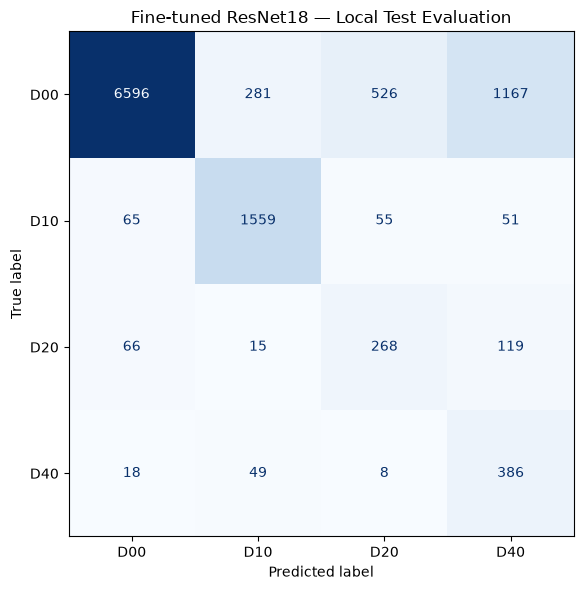

PASS: Classification report and confusion matrix saved.


In [16]:
#16
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

report = classification_report(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(RUN_DIR / "finetune_classification_report.csv")

cm = confusion_matrix(
    y_true, y_pred, labels=range(len(CLASSES))
)

pd.DataFrame(
    cm, index=CLASSES, columns=CLASSES
).to_csv(RUN_DIR / "finetune_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Fine-tuned ResNet18 — Local Test Evaluation")
fig.tight_layout()
fig.savefig(
    RUN_DIR / "finetune_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("PASS: Classification report and confusion matrix saved.")

### Local Evaluation Findings

The saved fine-tuned ResNet18 checkpoint was evaluated locally on
11,229 test crops. Accuracy (0.784487) and macro-F1 (0.619348)
matched the original reported results.

Performance differed substantially across classes:
- D00: F1 = 0.8614.
- D10: F1 = 0.8580.
- D20: F1 = 0.4045.
- D40: F1 = 0.3535.

The largest confusion involved 1,167 D00 crops predicted as D40.
D40 recall was high (0.8373), but precision was low (0.2240),
indicating many false-positive D40 predictions.

The test set is imbalanced, so accuracy should be interpreted
alongside macro-F1 and per-class metrics.

This verification reproduces evaluation of the saved checkpoint;
it does not reproduce model training from scratch.

-----------------------
## 17. Compare Top-2 Accuracy and Calibration

This cell calculates additional metrics from the test probabilities
without repeating model inference.

Top-2 accuracy measures how often the true class appears among
the two highest-probability predictions.

Expected Calibration Error (ECE) measures the weighted gap between
confidence and observed accuracy using ECE_BINS equal-width bins.

All four local metrics are compared with the original results.
A comparison passes when its absolute difference is at most
METRIC_TOLERANCE. Both settings are defined in Step 11.

The updated comparison table is saved to CSV.

In [17]:
# 17 — Compare metrics using the configured settings

top2 = np.argsort(y_prob, axis=1)[:, -2:]
local_top2 = np.mean(
    (top2 == y_true[:, None]).any(axis=1)
)

confidence = y_prob.max(axis=1)
correct = (y_pred == y_true)

bin_ids = np.minimum(
    (confidence * ECE_BINS).astype(int),
    ECE_BINS - 1
)

local_ece = 0.0
for bin_id in range(ECE_BINS):
    mask = bin_ids == bin_id
    if mask.any():
        local_ece += mask.mean() * abs(
            correct[mask].mean() - confidence[mask].mean()
        )

local_metrics["top2_accuracy"] = float(local_top2)
local_metrics["ece"] = float(local_ece)

comparison = pd.DataFrame({
    "Original": {
        key: float(original[key]) for key in local_metrics
    },
    "Local": local_metrics
})

comparison["Absolute difference"] = (
    comparison["Local"] - comparison["Original"]
).abs()

tolerance_column = f"Within tolerance ({METRIC_TOLERANCE:g})"
comparison[tolerance_column] = (
    comparison["Absolute difference"] <= METRIC_TOLERANCE
)

display(comparison)
comparison.to_csv(RUN_DIR / "finetune_comparison.csv")

print("Comparison saved.")

,Original,Local,Absolute difference,Within tolerance (1e-06)
accuracy,0.784487,0.784487,0.000000e+00,True
macro_f1,0.619348,0.619348,0.000000e+00,True
top2_accuracy,0.948793,0.948793,0.000000e+00,True
ece,0.065339,0.065339,3.645337e-08,True


Comparison saved.


--------------
## 18. Record the Verification Environment

This cell saves a summary of the verification scope, Python version,
operating system, device, and installed versions of the main packages.

The summary also records the class order, test set size, evaluation
settings, local metrics, and whether all metric comparisons passed.

Package versions are saved separately in requirements_local.txt.
This file records the listed packages; it is not a complete
environment lockfile and does not include every dependency.

In [18]:
# 18 — Record the verification environment and settings
import json
import platform
from importlib.metadata import version

packages = [
    "ipykernel", "numpy", "pandas", "matplotlib",
    "Pillow", "scikit-learn", "torch", "torchvision", "wandb"
]
package_versions = {
    name: version(name) for name in packages
}

verification = {
    "scope": "Saved finetune checkpoint evaluation; no retraining",
    "model": MODEL_NAME,
    "seed": SEED,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "device": str(device),
    "packages": package_versions,
    "torch_runtime_version": torch.__version__,
    "torchvision_runtime_version": torchvision.__version__,
    "classes": list(CLASSES),
    "test_crops": int(len(y_true)),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "ece_bins": ECE_BINS,
    "absolute_tolerance": METRIC_TOLERANCE,
    "local_metrics": {
        name: float(value)
        for name, value in local_metrics.items()
    },
    "all_compared_metrics_passed": bool(
        comparison[tolerance_column].all()
    )
}

(RUN_DIR / "verification_summary.json").write_text(
    json.dumps(verification, indent=2),
    encoding="utf-8"
)

(RUN_DIR / "requirements_local.txt").write_text(
    "\n".join(
        f"{name}=={value}"
        for name, value in package_versions.items()
    ) + "\n",
    encoding="utf-8"
)

print("PASS: Verification summary and local package versions saved.")

PASS: Verification summary and local package versions saved.


----
## 19. Record Input File Fingerprints

This cell computes SHA-256 fingerprints for six inputs:
the fine-tuned checkpoint, its configuration, the original test
comparison, and the three CSV data files.

Each record includes the filename, size in bytes, and SHA-256 hash.
The records are saved in input_fingerprints.json.

These fingerprints allow future runs to check whether the same
file contents were used. They do not establish file correctness.
The crop ZIP is not fingerprinted in this cell.

In [19]:
#19
import hashlib

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

files_to_record = {
    "finetune_checkpoint": checkpoint,
    "finetune_config": config_path,
    "original_test_comparison": ORIGINAL_RESULTS / "test_comparison.csv",
    "split_manifest": DATA_FILES["split_manifest.csv"],
    "classification_manifest": DATA_FILES["classification_manifest.csv"],
    "annotations": DATA_FILES["annotations.csv"],
}

fingerprints = {
    name: {
        "filename": Path(path).name,
        "size_bytes": Path(path).stat().st_size,
        "sha256": sha256_file(path)
    }
    for name, path in files_to_record.items()
}

(RUN_DIR / "input_fingerprints.json").write_text(
    json.dumps(fingerprints, indent=2),
    encoding="utf-8"
)

print(f"PASS: Fingerprints saved for {len(fingerprints)} input files.")

PASS: Fingerprints saved for 6 input files.


## Verification Summary

The notebook completed a clean, sequential run of all 19 code cells.

- All 32,692 referenced crops were present and decoded successfully.
- Parent-image split assignments were consistent.
- Norway images were reserved for testing.
- The saved fine-tuned ResNet18 was evaluated on 11,229 test crops.
- Accuracy, macro-F1, and top-2 accuracy matched the original values.
- The ECE difference was approximately 3.65e-08, within the 1e-6 tolerance.
- Evaluation outputs, environment details, and six input fingerprints
  were saved.

This verification covers data consistency checks and evaluation of
the saved fine-tuned checkpoint. It does not reproduce training or
independently evaluate the scratch and frozen checkpoints.